# KQC XMonsDirectCoupling — three directly coupled Swissmons with T-tapped readouts (Quantcore PDK rebuild)

**What the chip is.** KQCircuits' `chips/xmons_direct_coupling.py` (class `XMonsDirectCoupling`, default
parameters; © IQM Finland Oy, GPL-3.0, <https://github.com/iqm-finland/KQCircuits>; local copy
`other-libs/KQCircuits-main/.../kqcircuits/chips/xmons_direct_coupling.py`). Three Swissmon ("Finnmon") qubits sit
in a row at the chip centre; neighbouring arm tips face each other across their 24 µm gaps and a 10 µm ground
strip, which is the direct qubit–qubit coupling. Each qubit's coupler 1 feeds an 86 Ω readout resonator
(a = 5, b = 20 µm) that runs straight up to a T: the T's side arm (the "tail") makes up the resonator length and
ends shorted, its top arm tapers to 10/6 µm and couples through a 4-finger capacitor into a probe-line T at
y = 7900 µm. The probe line (NW → NE) has an input finger capacitor (8 fingers, 55.4 µm, "35 fF"). Every qubit has
a charge line and a flux line from an SMA8 launcher; four junction-test arrays sit on the edges.

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — it is
not a replica. We distribute the rebuild under GPL-3.0. The table says what is kept and what the PDK changes.

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` (dicing edge, IQM markers, labels) | same 10 × 10 mm (the SMA8 launchers sit on its edges; it does not fit the 7.5 mm die), Quantcore die frame: L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "XMDC" |
| launchers | SMA8, all eight, `launcher_indent` 800 µm (outer etch 20 µm from the edge) | SMA8, indent **880 µm** from the PDK pad rule (outer etch `frame.pad_edge` = 100 µm, 80 µm further in) |
| substrate | KQC simulation default silicon, εr 11.45 | sapphire 650 µm, εr 10.25 |
| junctions | KQC Manhattan SQUIDs (assumed L_J 16 nH, C_J 2 fF) | Quantcore Nb/AlOx/Nb trilayer SQUIDs, 2 × 0.25 × 0.6 µm, R_n 45 kΩ in parallel, L_J 6.73 nH, C_J 15 fF; the four junction-test arrays get the same SQUID |
| cheese | KQC's whole-area ground grid (`with_grid`, 5 µm holes on a 10 µm step, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band is drawn |
| elements, positions, routes | — | kept: every KQC element with the source's parameters, positions and orientations; launcher waypoints derived from the launcher ports |
| placement | centred | centred (checked below, no shift) |

**Kept exactly:** the three `Swissmon`s with KQC's per-qubit parameters (coupler lengths 158/140/158 µm, coupler
gaps 90/102/90 µm, charge-line offsets) at x = 4650, 5000, 5350 µm; per readout the chain probe-line
`WaveguideCoplanarSplitter` → `FingerCapacitorSquare` (60.8 / 61.55 / 58.1 µm fingers) → `WaveguideCoplanarTaper`
(5/20 → 10/6 µm, 100 µm) → 86 Ω `WaveguideCoplanarSplitter`, snapped port to port as KQC aligns them; the
straight to the qubit; the tail with KQC's length formula (totals 4868.6 / 4682.3 / 4686.7 µm); the input
capacitor 300 µm left of QB1; the charge- and flux-line paths; the junction-test arrays.

**Simplified:** the `n_bridges` airbridges along the lines are left out.

**LOM approximations (stated):** the qubit–qubit coupling is a *declared* coupling (`d.couple`) with an
**assumed 0.3 fF** (no route or snap carries it; the C-matrix of the `qubits` sim group replaces it). The T-tapped
readout (straight + 86 Ω T + shorted tail) is one λ/4 `TLres` with the summed length.

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the die with its eight SMA8 launchers, the launchers and the pad rule, the three Swissmons with the junction-test arrays (first: each readout chain is placed at its qubit's coupler), the readout chains and the probe line, the T-tapped λ/4 readouts, the declared direct coupling, the charge and flux lines, and then the whole chip (the sim groups, the centring, the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `xmonsdirectcoupling.v1.ipynb`; both save the same `xmonsdirectcoupling.json`.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/xmonsdirectcoupling/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.circuit.bridges import junction_from_fingers

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc")                            # design JSON + final snapshots
STEPS = Path("build/snapshots/xmonsdirectcoupling")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way a designer lays it out by hand: the die and its launchers, the qubits, the readout line,
the readout resonators, the coupling, the control lines, and then the whole chip. Each segment is one cell with one
picture of the chip so far (live, KLayout redraws after every cell).

**Why the qubits come before the readout line here.** Each readout chain hangs at its qubit's coupler x: the
probe-line T sits at `port_xy(d, "QB<i>.cplr1")` (x) and y = 7900 µm, the rest of the chain is snapped port to port
below it, and the input capacitor sits 300 µm left of QB1's T. So the readout line follows the qubits; the calls keep
the v1's order and nothing is recomputed to put the line first. KQC's ground grid (`with_grid`, ≈ 0.8 M holes) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame and the SMA8 sample holder's eight launchers |
| 2 | the launchers and the pad rule (they come with the die: a look and a table) |
| 3 | the qubits: three Swissmons in a row with their trilayer SQUIDs, and the four junction-test arrays |
| 4 | the readout line: per qubit the chain probe-line T → finger capacitor → taper → 86 Ω T, the input capacitor, the probe line NW → NE |
| 5 | the readout resonators: per qubit the straight `RS` (86 Ω T → coupler 1) and the shorted tail `RR` |
| 6 | the coupling: the direct coupling of facing arm tips, declared (`d.couple`, an assumed 0.3 fF) |
| 7 | the control routing: three charge lines and three flux lines |
| 8 | the whole chip: sim groups, centring, save |

## Design 1 · The die, its frame and the launchers

`Designer(...)` starts the chip: the 10 × 10 mm box, all eight SMA8 sample-holder launchers (KQC's default names
NW, NE, EN, ES, SE, SW, WS, WN) and the chip name "XMDC", which the Quantcore frame writes as the device ID on a
free edge. `with_grid=True` asks for KQC's whole-area ground grid (the original's cheese): the PDK band is then not
added (chip `cheese` stays `"auto"`).

The frame itself is the PDK default: L dicing markers on 1000/0 at the corners, 3 × 3 alignment grids on 1001/0
and the chip boundary on 100/0. KQC's own `ChipFrame` is not drawn.

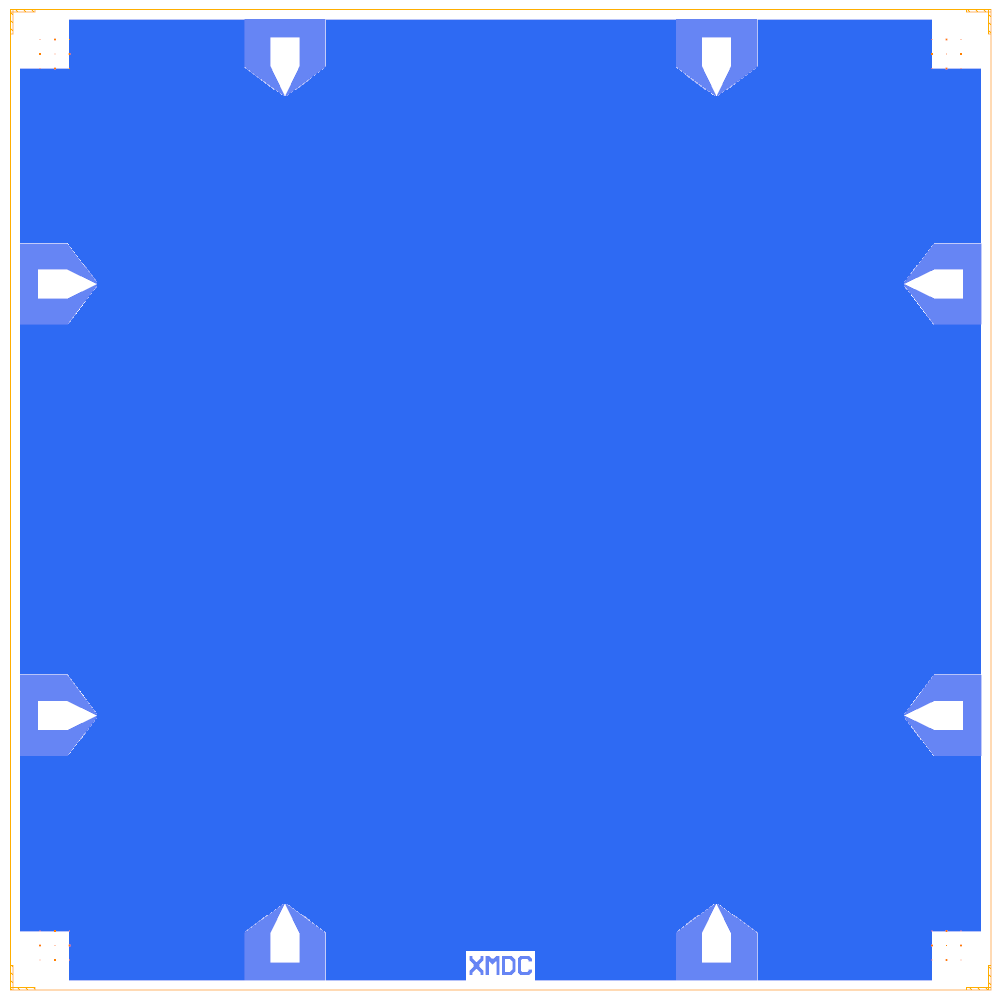

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout. The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the pad count stays 0.

WindowsPath('build/snapshots/xmonsdirectcoupling/1_die.png')

In [5]:
d = Designer("xmonsdirectcoupling", box=(0, 0, 10000, 10000), launchers="SMA8",
             chip={"name_chip": "XMDC", "with_grid": True}, live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP,
            note="The SMA8 launchers belong to the chip (the sample holder), not to the instances, so the "
                 "pad count stays 0.")

## Design 2 · Bond pads: the launchers and the pad rule

**PDK rule:** a bond pad's or launcher's outer etch edge sits `frame.pad_edge` (100 µm) from the die edge. For KQC
sample-holder launchers the Designer applies it by computing `launcher_indent` (die edge → launcher port): RF
launcher = 100 µm + taper (300 µm) + pad (300 µm) + frame gap (180 µm) = **880 µm** (KQC: 800 µm, i.e. the outer
edge 20 µm from the edge). Every route (Designs 4 and 7) starts from these ports or from waypoints derived from them, so
nothing else moves with the rule. (Stand-alone pads, e.g. a `BondPad`, take `edge="auto"` in `d.add` instead; this
chip has none.)

The launchers came with the die (Design 1): nothing is added here. The table measures them, the picture zooms on NW.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| chip.NW | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.NE | launcher port | n | port 880 µm in (indent from the rule) | ✓ |
| chip.EN | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.ES | launcher port | e | port 880 µm in (indent from the rule) | ✓ |
| chip.SE | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.SW | launcher port | s | port 880 µm in (indent from the rule) | ✓ |
| chip.WS | launcher port | w | port 880 µm in (indent from the rule) | ✓ |
| chip.WN | launcher port | w | port 880 µm in (indent from the rule) | ✓ |

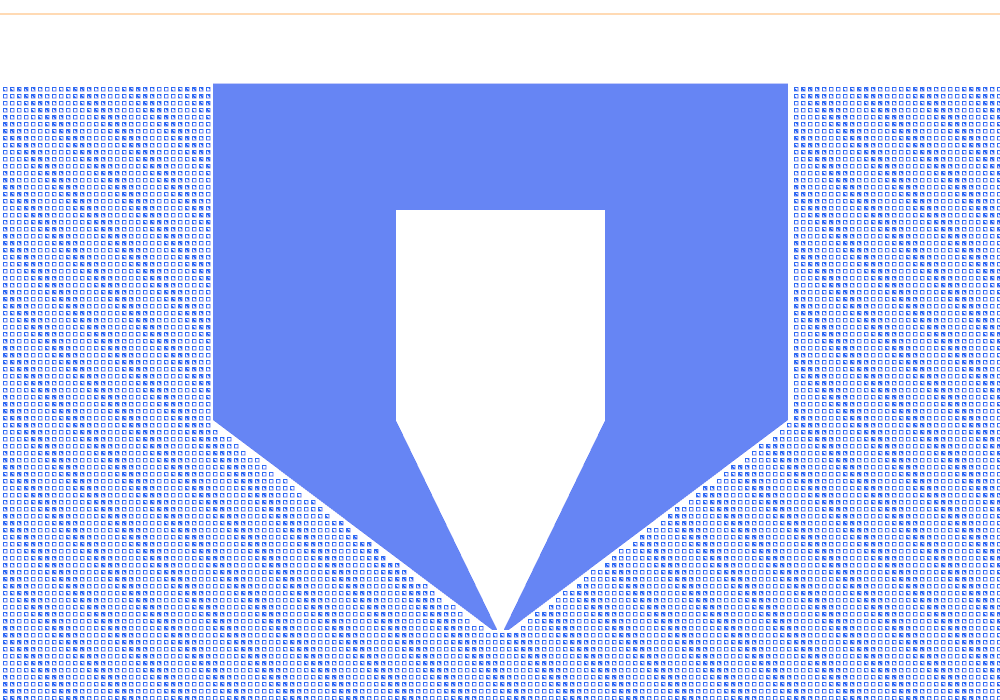

In [6]:
display(Markdown(pads_md(d)))
x, y = port_xy(d, "chip.NW")
snap(d, STEPS / "2_launcher.png", box=(x - 400, y - 100, x + 400, 10000 + 20), size=(1000, 700), width=420);

## Design 3 · Qubit placement: three Swissmons (before the readout line)

**The junction from the PDK rule.** KQC draws a SQUID in every Swissmon. `trilayer_junction` turns it into the
Quantcore trilayer SQUID: two junctions whose straight finger is KQC's `junction_width` (the bent finger stays at
the PDK 0.6 µm). With the nominal L_J (6.73 nH, the 0.5 × 0.6 µm junction at R_n 45 kΩ) as the SQUID's parallel
total, each junction is 0.25 × 0.6 µm. `JJ_PARAMS` go on the cell, `JUNCTION` (L_J, C_J) is what the LOM and the
FEM junction ports use.

**Qubits.** Three KQC `Swissmon`s on y = 5000 µm: 146 µm arms, 24 µm arm width and gap, port widths 10/5/10 µm,
only coupler 1 drawn (`cpl_length` [0, 158 | 140 | 158, 0]). The step between centres is 24 + 24 + 2 × 146 µm,
plus the 10 µm ground strip between facing arm tips. Ports: `cplr0`–`cplr2`, `drive`, `flux`. The SQUID carries
the trilayer junction parameters of the cell below.

**Junction-test arrays.** KQC's `JunctionTestPads` on the four edges (1300 × 2500 µm areas, horizontal
junctions), with the same trilayer SQUID.

The first picture is the chip so far, the second zooms on the three qubits (no rebuild: the same build).

In [7]:
LJ_PDK = trilayer_junction("Swissmon")[1]["Lj_nH"]          # PDK nominal L_J (0.5 × 0.6 µm junction, R_n 45 kΩ)
JJ_PARAMS, JUNCTION = trilayer_junction("Swissmon", lj_nH=LJ_PDK, squid=True)
print("cell parameters:", JJ_PARAMS)
print("LOM junction:   ", JUNCTION)

cell parameters: {'junction_type': 'Quantcore Squid', 'junction_width': 0.25}
LOM junction:    {'Lj_nH': 6.7344, 'Cj_fF': 15.0}


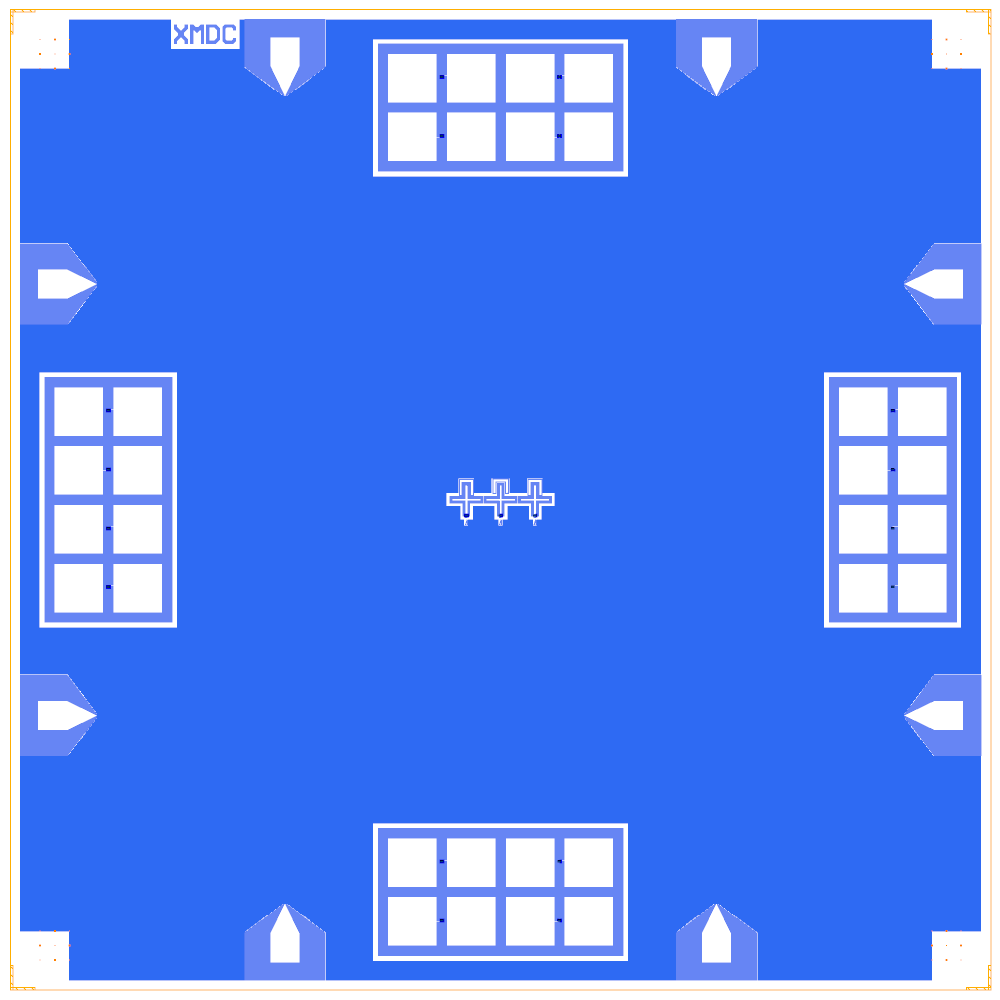

**On the chip so far:** 0 pads · 0 qubits · 7 other components · 0 routes · 0 declared couplings. **This step added** 7 component(s) `JT_W`, `JT_S`, `JT_E`, `JT_N`, `QB1`, `QB2`, `QB3`. KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among the other components.

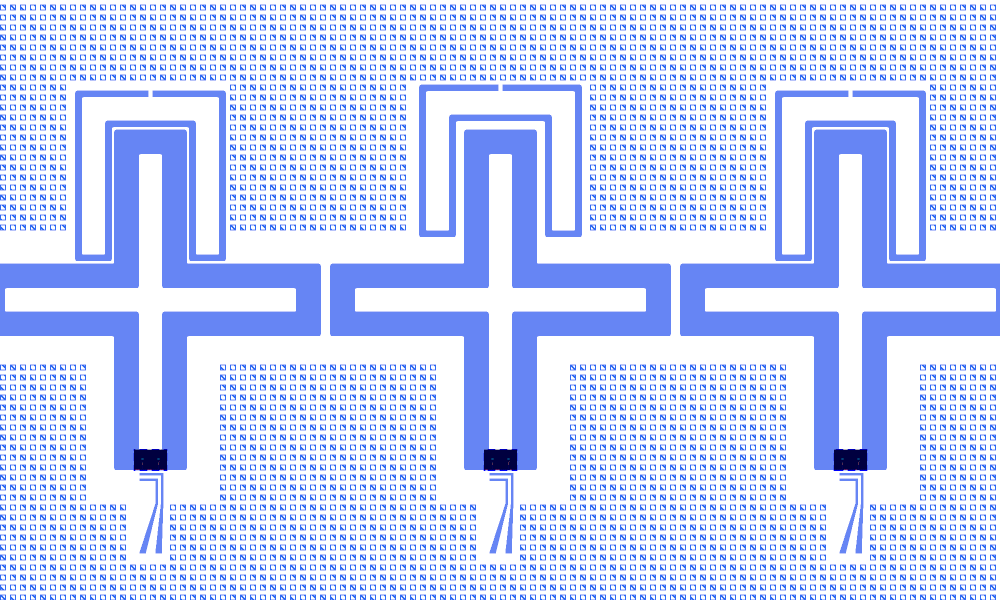

In [8]:
with d.batch():
    JTP = "kqcircuits.test_structures.junction_test_pads.junction_test_pads.JunctionTestPads"
    for name, at, (w, h) in (("JT_W", (350, 3750), (1300, 2500)), ("JT_S", (3750, 350), (2500, 1300)),
                             ("JT_E", (8350, 3750), (1300, 2500)), ("JT_N", (3750, 8350), (2500, 1300))):
        d.add(name, JTP, at=at, margin=50, area_width=w, area_height=h, junctions_horizontal=True, **JJ_PARAMS)

    # qubits: arm tips 24 + 10 + 24 µm apart (KQC qubit_step + qubit_spacing)
    common = dict(arm_length=[146] * 4, island_r=2, port_width=[10, 5, 10], arm_width=[24] * 4, gap_width=[24] * 4)
    step = 24 + 24 + 2 * 146
    qubits = {
        "QB1": (5000 - step - 10, dict(cpl_gap=[110, 90, 110], cpl_length=[0, 158, 0], cl_offset=[150, -150])),
        "QB2": (5000, dict(cpl_gap=[110, 102, 110], cpl_length=[0, 140, 0], cl_offset=[150, 150])),
        "QB3": (5000 + step + 10, dict(cpl_gap=[110, 90, 110], cpl_length=[0, 158, 0], cl_offset=[-150, -150])),
    }
    for n, (x, own) in qubits.items():
        d.add(n, "Swissmon", at=(x, 5000), cpl_width=[60, 24, 60], junction=JUNCTION, **JJ_PARAMS, **common, **own)
layout_step(d, STEPS / "s3_qubits.png", **CHIP,
            note="KQC's qubit cells carry no Quantcore qubit category yet, so this line counts them among "
                 "the other components.")
snap(d, STEPS / "s3_qubits_zoom.png", box=(4500, 4700, 5500, 5300), size=(1000, 600), width=420);

## Design 4 · Readout: the readout chains and the probe line

**Readout chains.** Per qubit, from the probe line down: a probe-line T (`WaveguideCoplanarSplitter`, arms
11/11/31 µm) at the qubit's x and y = 7900 µm; the 4-finger `FingerCapacitorSquare` snapped to its bottom arm; a
`WaveguideCoplanarTaper` 10/6 → 5/20 µm (100 µm long); the 86 Ω T (arms 22.5/22.5/62.5 µm, a = 5, b = 20 µm).
`snap=` places each by one port onto the previous one's port, as KQC aligns them.

**Probe line.** NW → the input finger capacitor (8 fingers, 55.4 µm; 300 µm left of QB1's T) → the three T's →
NE, at y = 7900 µm; the legs from NW and NE turn at the launcher's x.

The resonators themselves (the straight and the tail of each chain) follow in Design 5.

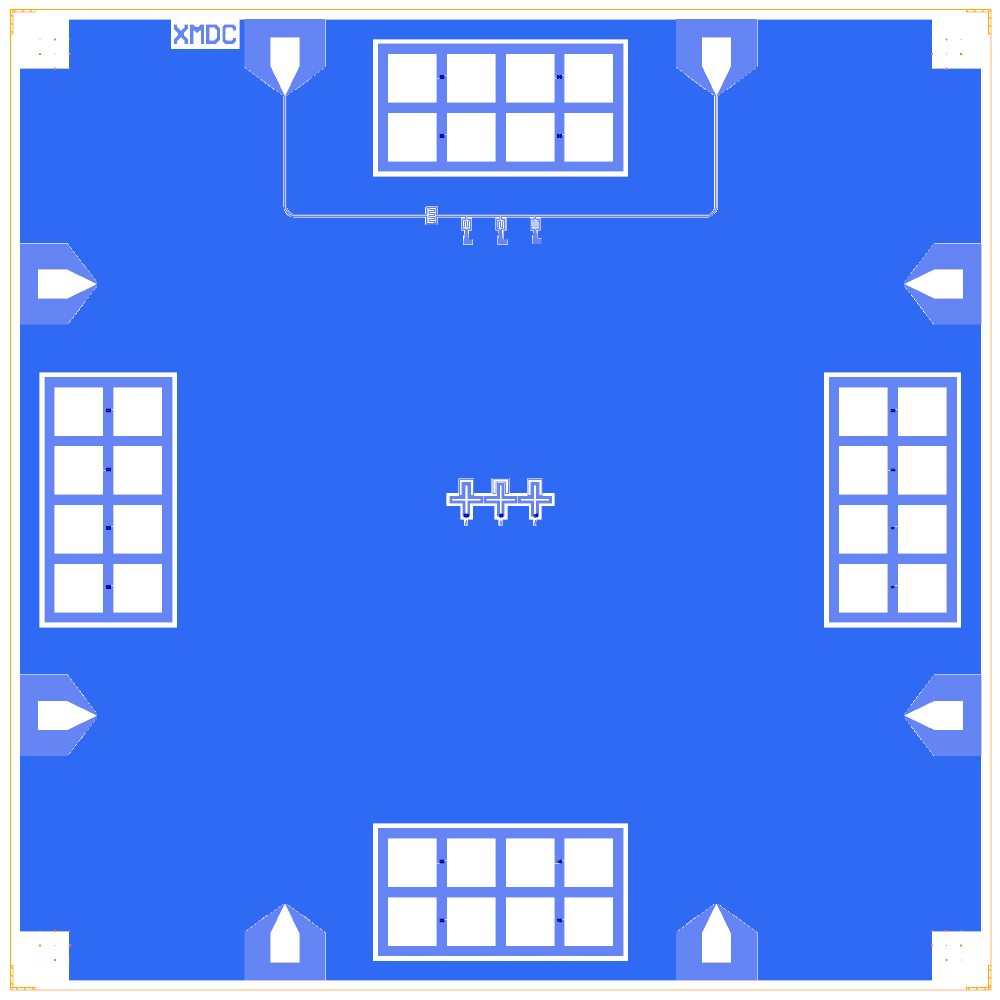

**On the chip so far:** 0 pads · 0 qubits · 20 other components · 5 routes · 0 declared couplings. **This step added** 13 component(s) `PL1`, `RC1`, `TP1`, `RX1`, `PL2`, `RC2`, `TP2`, `RX2` … (+5) and 5 route(s) `P0`, `P1`, `P2`, `P3`, `P4`.

WindowsPath('build/snapshots/xmonsdirectcoupling/s4_readout_line.png')

In [9]:
def corner(ref, dist=100.0):                     # KQC "<port>_corner": one turn radius out along the port
    x, y, a = port_info(d, ref)
    return (x + dist * math.cos(math.radians(a)), y + dist * math.sin(math.radians(a)))


TOTAL = {1: 2421.5 + 2447.1, 2: 2436 + 2246.3, 3: 2438.5 + 2248.2}   # KQC readout totals (µm)
FINGERS = {1: 60.8, 2: 61.55, 3: 58.1}                              # finger-capacitor finger lengths (µm)
with d.batch():
    for i in (1, 2, 3):
        qx, qy = port_xy(d, f"QB{i}.cplr1")
        tee = d.add(f"PL{i}", "WaveguideCoplanarSplitter", at=(qx, 7900), lengths=[11, 11, 31],
                    port_names=["right", "left", "bottom"])
        cap = d.add(f"RC{i}", "FingerCapacitorSquare", snap="b", to=tee.bottom, finger_number=4,
                    finger_length=FINGERS[i], finger_gap_end=5, finger_gap=5, finger_width=15, ground_padding=10)
        tap = d.add(f"TP{i}", "WaveguideCoplanarTaper", snap="b", to=cap.a, a=5, b=20, a2=10, b2=6, taper_length=100)
        rx = d.add(f"RX{i}", "WaveguideCoplanarSplitter", snap="right", to=tap.a, lengths=[22.5, 22.5, 62.5],
                   a_list=[5, 5, 5], b_list=[20, 20, 20], port_names=["right", "left", "bottom"])
with d.batch():
    nwx, _ = port_xy(d, "chip.NW")
    nex, _ = port_xy(d, "chip.NE")
    q1x, _ = port_xy(d, "QB1.cplr1")
    pin = add_aligned(d, "IN", "FingerCapacitorSquare", "b", (q1x - 300, 7900), finger_number=8, finger_length=55.4,
                      finger_gap_end=5, finger_gap=5, finger_width=15, ground_padding=10)
    d.route("P0", "chip.NW", pin.a, nodes=[(nwx, 7900)])
    d.route("P1", pin.b, "PL1.left")
    d.route("P2", "PL1.right", "PL2.left")
    d.route("P3", "PL2.right", "PL3.left")
    d.route("P4", "PL3.right", "chip.NE", nodes=[(nex, 7900)])
layout_step(d, STEPS / "s4_readout_line.png", **CHIP)

## Design 5 · Readout: the T-tapped λ/4 resonators

The straight `RS` runs from the
86 Ω T to the qubit's coupler 1 (a = 5, b = 20 µm); the tail `RR` leaves the T's third arm, turns down and ends
shorted (`d.free_end(..., term=0)`). KQC's formula gives the tail length from the total: total − straight − T arm
− the 90° bend + one radius.

The printed totals (straight + T + tail) are KQC's: 4868.6 / 4682.3 / 4686.7 µm.

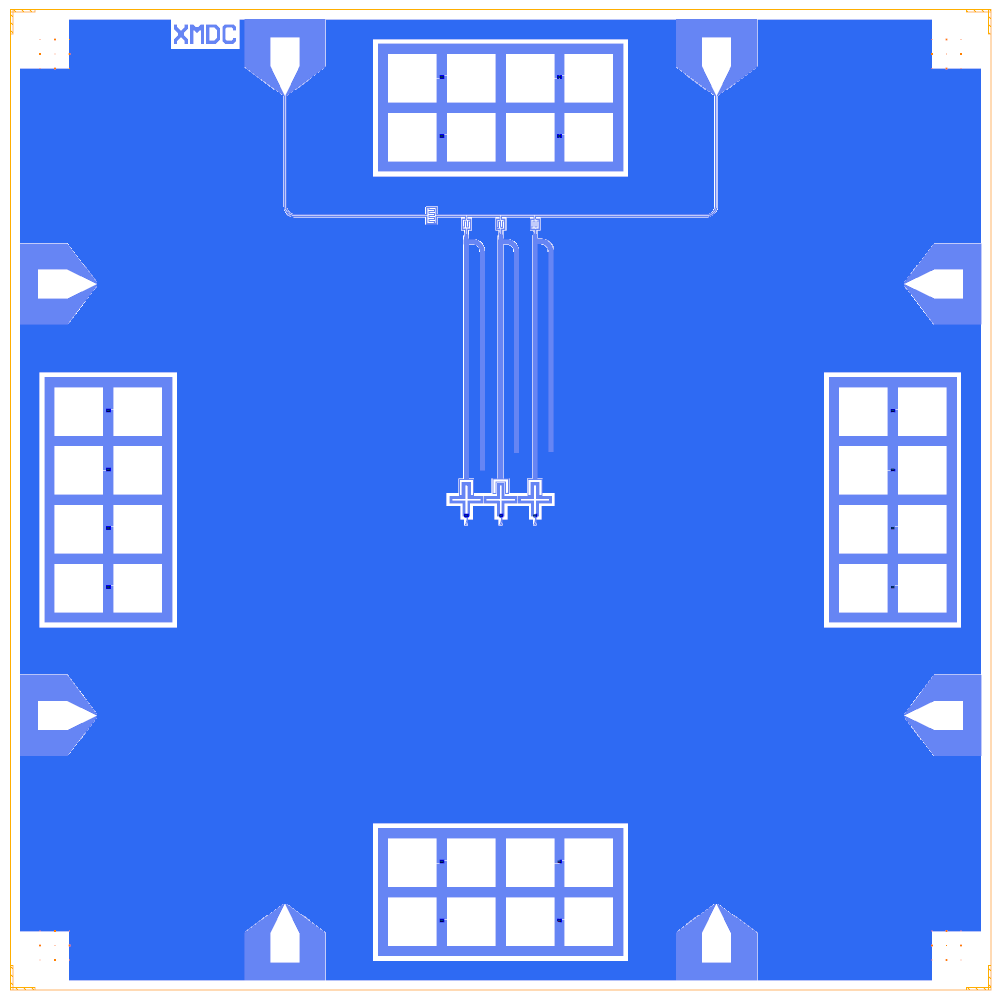

**On the chip so far:** 0 pads · 0 qubits · 20 other components · 11 routes · 0 declared couplings. **This step added** 6 route(s) `RS1`, `RR1`, `RS2`, `RR2`, `RS3`, `RR3`.

{'readout 1': 4868.6, 'readout 2': 4682.3, 'readout 3': 4686.7} (straight + T + tail; KQC totals 4868.6 / 4682.3 / 4686.7)


In [10]:
with d.batch():
    for i in (1, 2, 3):
        qx, qy = port_xy(d, f"QB{i}.cplr1")
        rx = d[f"RX{i}"]                         # the chain's 86 Ω T (Design 4)
        d.route(f"RS{i}", rx.left, f"QB{i}.cplr1", a=5, b=20)
        (lx, ly), (rgx, rgy) = port_xy(d, f"RX{i}.left"), port_xy(d, f"RX{i}.right")
        non_tail = math.hypot((lx + rgx) / 2 - qx, (ly + rgy) / 2 - qy)
        tail = TOTAL[i] - non_tail - 62.5 - math.pi / 2 * 100 + 100
        cx, cy = corner(f"RX{i}.bottom")
        d.route(f"RR{i}", rx.bottom, d.free_end((cx, cy - tail), dir=90, term=0), a=5, b=20, r=100)
layout_step(d, STEPS / "s5_readouts.png", **CHIP)
lengths = d.result.route_lengths()
print({f"readout {i}": round(lengths[f"RS{i}"] + 62.5 + 45 / 2 + lengths[f"RR{i}"], 1) for i in (1, 2, 3)},
      "(straight + T + tail; KQC totals 4868.6 / 4682.3 / 4686.7)")

## Design 6 · Coupling: the direct coupling, declared

**The direct coupling.** Nothing in the layout joins the facing arm tips (they couple through the 24 + 10 + 24 µm
gap), so the LOM cannot see it from the netlist. `d.couple` declares it: an assumed 0.3 fF between neighbouring
islands, replaced by the `qubits` C-matrix once that job is solved.

A declared coupling has no geometry, so this segment draws nothing (no picture, no rebuild); the cell lists the
couplings and the counts so far.

In [11]:
with d.batch():
    d.couple("C12", "QB1", "QB2", C_fF=0.3, note="arm tips facing across 24 + 10 + 24 µm (assumed value)")
    d.couple("C23", "QB2", "QB3", C_fF=0.3, note="arm tips facing across 24 + 10 + 24 µm (assumed value)")
display(Markdown("| coupling | between | type | value (fF) | note |\n|---|---|---|---|---|\n" + "\n".join(
    f"| `{k}` | {' – '.join(c['between'])} | {c['type']} | {c['value']} | {c.get('note', '')} |"
    for k, c in d.data["couplings"].items())))
print("on the chip so far:", on_chip(d))

| coupling | between | type | value (fF) | note |
|---|---|---|---|---|
| `C12` | QB1 – QB2 | C | 0.3 | arm tips facing across 24 + 10 + 24 µm (assumed value) |
| `C23` | QB2 – QB3 | C | 0.3 | arm tips facing across 24 + 10 + 24 µm (assumed value) |

on the chip so far: {'pads': 0, 'qubits': 0, 'components': 20, 'routes': 11, 'couplings': 2, 'sim_groups': 0}


## Design 7 · Routing: the charge and flux lines

**Charge lines** (6 µm open end at the drive
port) and **flux lines** follow KQC's paths; their waypoints come from the launcher ports.

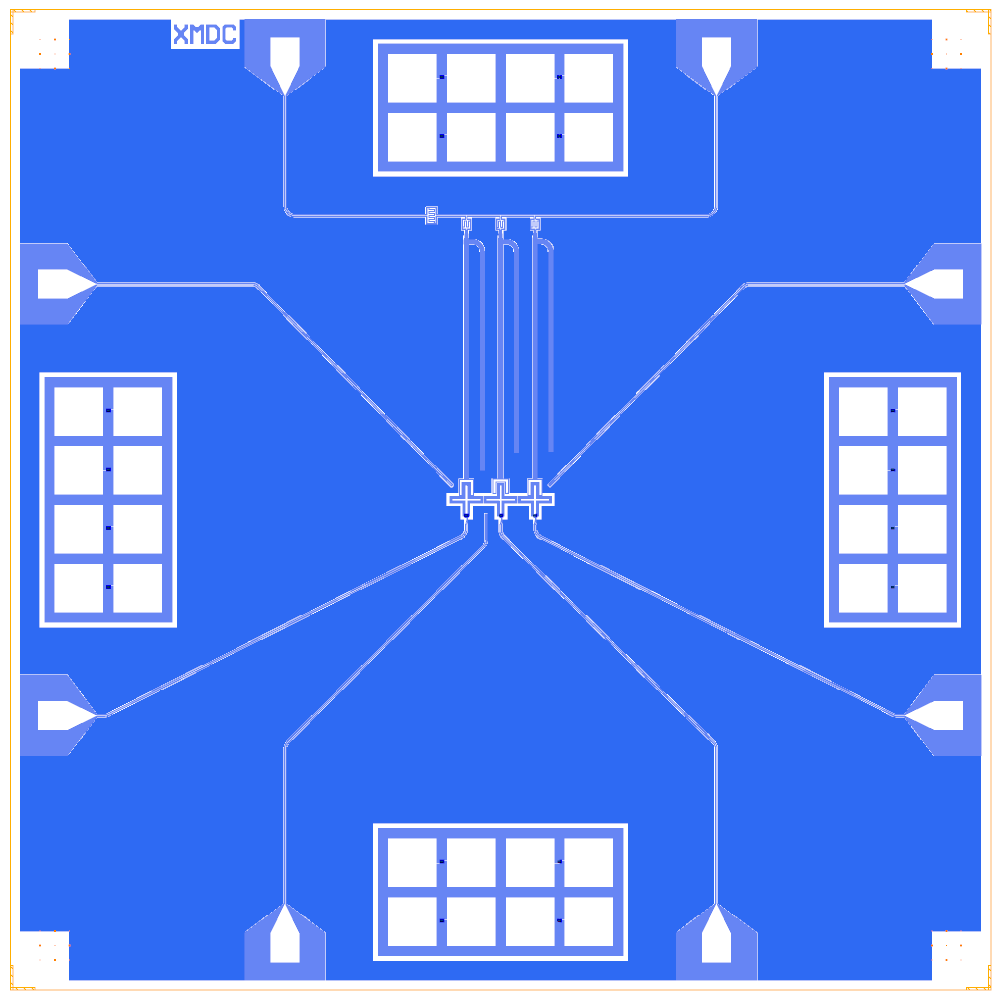

**On the chip so far:** 0 pads · 0 qubits · 20 other components · 17 routes · 2 declared couplings. **This step added** 6 route(s) `DL1`, `FL1`, `DL2`, `FL2`, `DL3`, `FL3`.

WindowsPath('build/snapshots/xmonsdirectcoupling/s7_control.png')

In [12]:
with d.batch():                                  # nwx, nex: the NW / NE launcher x (Design 4)
    _, wny = port_xy(d, "chip.WN")
    _, wsy = port_xy(d, "chip.WS")
    swx, _ = port_xy(d, "chip.SW")
    sex, _ = port_xy(d, "chip.SE")
    _, esy = port_xy(d, "chip.ES")
    _, eny = port_xy(d, "chip.EN")
    d2x, d2y = port_xy(d, "QB2.drive")
    d.route("DL1", "chip.WN", "QB1.drive", nodes=[(nwx - 300, wny)], term2=6)
    d.route("FL1", "chip.WS", "QB1.flux", nodes=[corner("chip.WS"), corner("QB1.flux")])
    d.route("DL2", "chip.SW", "QB2.drive", nodes=[(swx, wsy - 300), (d2x, d2y - 300)], term2=6)
    d.route("FL2", "chip.SE", "QB2.flux", nodes=[(sex, esy - 300), corner("QB2.flux")])
    d.route("DL3", "chip.EN", "QB3.drive", nodes=[(nex + 300, eny)], term2=6)
    d.route("FL3", "chip.ES", "QB3.flux", nodes=[corner("chip.ES"), corner("QB3.flux")])
layout_step(d, STEPS / "s7_control.png", **CHIP)

## Design 8 · The whole chip: sim groups, centring, save

**Sim groups and centring.** A sim group names a FEM sub-problem: the three qubits together (Q3D C-matrix: it
gives the real direct couplings) and each qubit with its readout chain. `center_in_die` checks that the content
sits centred in the die (PDK placement rule) and shifts it if it is more than 50 µm off — here it is centred, so
nothing moves. Then the design is saved: `xmonsdirectcoupling.json` is what DRC, LOM, FEM and `qcc` read. `save_design`
compares it with the file it replaces (the previous run's): the segments above changed how the chip is built (the
routes and the couplings in another order), not the chip, so it should say *same design*; the file keeps the
previous key order.

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/xmonsdirectcoupling.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer xmonsdirectcoupling: 20 instances, 17 routes, live=False> → examples\designs\kqc\xmonsdirectcoupling.json


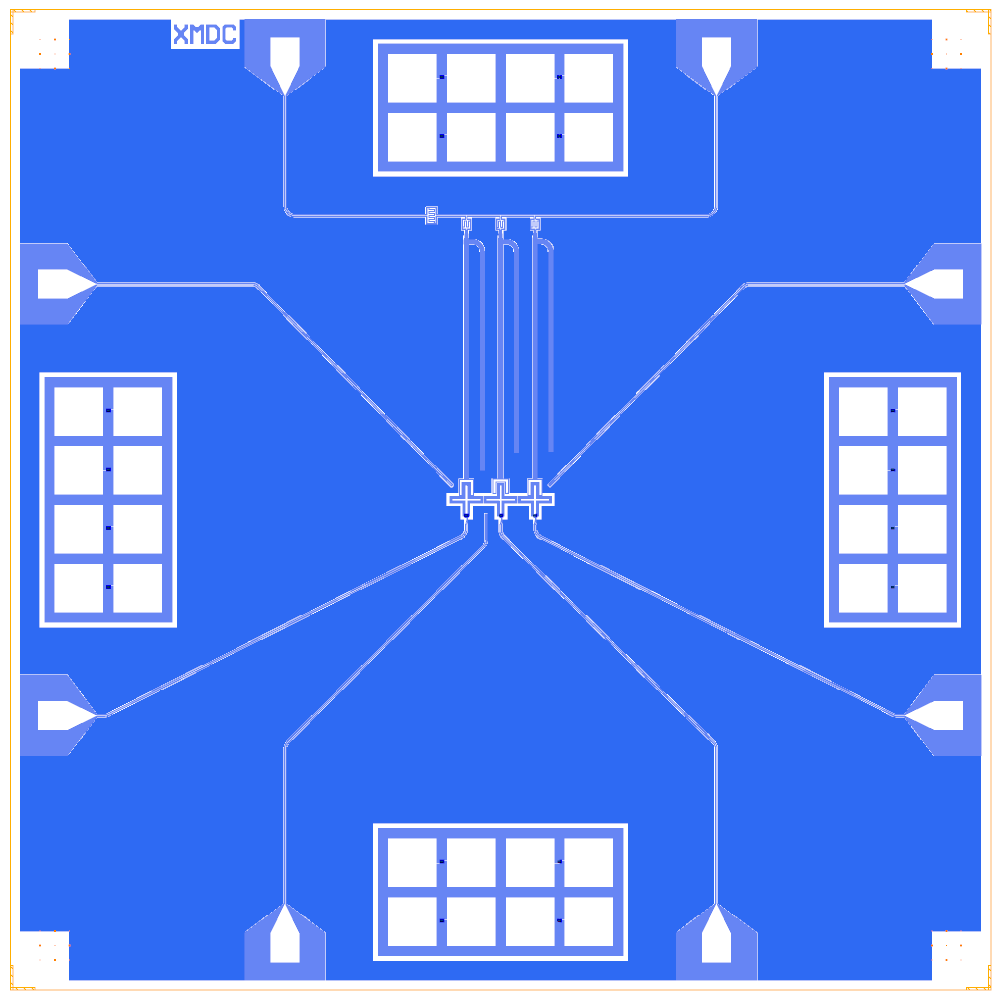

**On the chip so far:** 0 pads · 0 qubits · 20 other components · 17 routes · 2 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/xmonsdirectcoupling/4_routes.png')

In [13]:
d.sim_group("qubits", ["QB1", "QB2", "QB3"], analyses=["q3d_cmatrix"])
for i in (1, 2, 3):
    d.sim_group(f"QB{i}_RR{i}", [f"QB{i}", f"RS{i}", f"RX{i}", f"RR{i}"], analyses=["q3d_cmatrix"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "xmonsdirectcoupling.json")
display(Markdown(same))
print(d, "→", DESIGN)
layout_step(d, STEPS / "4_routes.png", **CHIP)

# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** DRC clean, with 6 `dangling_port` warnings: each Swissmon's zero-length couplers 0 and 2 (`cpl_length` [0, …, 0]; the LOM puts their ports on ground). No PDK design warning: the SQUIDs' device R_n is 45 kΩ (the parallel R_n of two 90 kΩ junctions) and f_q (≈ 6.5 GHz) is inside the 4–8 GHz band. `pdk_report` gives KQC's grid as the cheese ("the original design's own"), the content centred (0, 0) and "Quantcore Squid × 3" (the qubits; the junction-test arrays draw the same SQUID but are not counted).

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit: each component's LOM model maps its ports to circuit nodes,
routes join nodes (or become transmission-line resonators), launchers are 50 Ω ports or drive / flux controls.

Swissmon → an island node (C and the SQUID to ground) and a coupler-1 node (C_g to the island, C to ground). The
declared couplings C12 and C23 join neighbouring islands. The readout straight, the 86 Ω T and the tail form one
λ/4 `TLres` (shorted at the tail's end); the taper and the finger capacitor couple it to the probe line, which runs
between the NW and NE 50 Ω ports through the input capacitor. Charge and flux lines are drive / flux controls on
the SQUIDs.

In [ ]:
lb = d.lom()
show_netlist(lb)
display(Markdown("**QB1's ports → circuit nodes:**\n\n| port | node |\n|---|---|\n" + "\n".join(
    f"| `{ref}` | `{node}` |" for ref, node in sorted(lb.port_map.items()) if ref.startswith("QB1."))))

# LOM: simulate the lumped circuit, and plot it

## LOM 1 · The LOM simulation

QuCat finds the normal modes of the circuit (frequencies, κ into the 50 Ω ports, anharmonicities) and QuTiP
diagonalises the dressed Hamiltonian of the first modes (f_q, α, f_r, χ). First the three qubits with their declared
couplings; then each qubit with its readout chain and the whole probe line.

The three qubits are identical in the LOM (the same SQUID and nearly the same capacitances), so with the 0.3 fF
couplings their modes hybridise: each mode spreads over two or three junctions, and a per-pair static ZZ is not
defined (the ZZ table says so). LOM 3 detunes one qubit to show the difference.

In [ ]:
qubits_only = simulate_groups(d, {"QB1–QB2–QB3": ["QB1", "QB2", "QB3"]}, max_modes=3, excitations=[4, 4, 4])
display(Markdown("**Coupled qubits, QuCat normal modes:**\n\n" + modes_md(qubits_only["QB1–QB2–QB3"])))
display(Markdown("**Static ZZ (QuTiP; QB1–QB2 and QB2–QB3 are neighbours through C12, C23):**\n\n"
                 + zz_md(qubits_only)))

In [ ]:
probe = ["IN", "PL1", "PL2", "PL3", "P0", "P1", "P2", "P3", "P4"]
groups = {f"QB{i}+RR{i}": [f"QB{i}", f"RS{i}", f"RX{i}", f"TP{i}", f"RC{i}", f"RR{i}"] + probe for i in (1, 2, 3)}
results = simulate_groups(d, groups)
display(Markdown(groups_md(results)))

**Reading the numbers (from the v1 run).** With the PDK SQUIDs the three coupled qubits sit at 6.74–6.78 GHz (KQC's assumed 16 nH gave ≈ 4.5 GHz). Each mode is spread over two or three junctions (participations 0.32–0.64), so the ZZ table reports every pair as hybridised. With their readout chains and the probe line: f_q 6.52 / 6.54 / 6.52 GHz, α ≈ −255 MHz; the λ/4 readouts at 5.20 / 5.42 / 5.38 GHz (below the qubits), κ 10.2 / 11.6 / 10.4 MHz, χ −2.3 / −2.9 / −3.5 MHz. The LOM merges straight + T + tail into one λ/4 of 4784 / 4597 / 4602 µm (the builder notes in Check 2).

## LOM 2 · The LOM in two plots

The same results as pictures: (a) every normal mode of the three coupled qubits and of each qubit–readout group
(QuCat; circles are qubits, squares the readouts; filled markers are the QuTiP dressed values), (b) the dispersive
shift |χ| of each readout. In the v1 run the λ/4 readouts sit ≈ 1.1–1.3 GHz below the qubits.

In [ ]:
plot_lom({**qubits_only, **results}, STEPS / "lom.png", title="xmonsdirectcoupling: LOM per sub-circuit")

## LOM 3 · One geometry change, by hand

Before the FEM, a design step by hand. A design change is a parameter change in the design, followed by a rebuild and a new LOM run. Here: give QB2 a
0.27 µm straight junction finger instead of 0.25 µm (L_J 6.73 → 6.24 nH, R_n 45.0 → 41.7 kΩ, still in the
window). QB2 moves up in frequency, away from QB1 and QB3; the table shows which modes this separates. The change
is made on a copy (`design_copy`), so `xmonsdirectcoupling.json` keeps the
nominal SQUID.

In [ ]:
d2 = design_copy(DESIGN)
j = junction_from_fingers(0.27, 0.6, n=2)
d2["QB2"].set(junction_width=0.27, junction={"Lj_nH": round(j.lj_nH, 4), "Cj_fF": round(j.cj_fF, 3)})
after = simulate_groups(d2, {"QB1–QB2–QB3": ["QB1", "QB2", "QB3"]}, max_modes=3, excitations=[4, 4, 4])


def mode_rows(r):                                # QuCat modes: f and the junction participations (> 5 %)
    return {m.label: (m.f_GHz, ", ".join(f"{k} {v:.2f}" for k, v in m.participation.items() if v > 0.05))
            for m in r.modes if m.kind == "qubit"}


b, a = mode_rows(qubits_only["QB1–QB2–QB3"]), mode_rows(after["QB1–QB2–QB3"])
display(Markdown("**QB2 straight finger 0.25 → 0.27 µm**\n\n"
                 "| mode | before: f (GHz) · participation | after: f (GHz) · participation |\n|---|---|---|\n"
                 + "\n".join(f"| {k} | {b[k][0]:.4f} · {b[k][1]} | {a[k][0]:.4f} · {a[k][1]} |"
                             for k in sorted(set(a) & set(b)))))
display(Markdown("**Static ZZ after:**\n\n" + zz_md(after)))

**Result (from the v1 run).** QB2 moves from 6.779 to 6.982 GHz (+203 MHz) and now lives on its own junction (participation 0.99). QB1 and QB3 stay hybridised with each other (0.50 / 0.50, at 6.755 / 6.756 GHz): they are mirror images, coupled through QB2, so detuning QB2 alone does not separate them, and the ZZ table still reports every pair as hybridised. A per-pair ZZ needs all three detuned (a second change, e.g. QB3 at 0.24 µm) or the C-matrix of the `qubits` group.

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: export to HFSS, the component and eigenmode simulations, the full-wave run

The plugin's *Simulate* step. The LOM above uses analytic capacitance estimates; a finite-element job measures them.
Each job is a sim group cut out of the chip, written to `build/jobs/<design>_<group>_<analysis>/`. With
`RUN_FEM = False` (the default) the jobs are only exported: the cells load results that were solved and kept before
(in `examples/designs/kqc/fem/<job>/`), and otherwise say what would appear.

## Simulate 1 · Export to HFSS

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

`FEM_FAST` (the switch at the top) picks the fast test settings for every job exported from here on. With
`RUN_FEM = True` the next cells solve each Ansys job in a **new batch, non-graphical** AEDT 2024 R1 (or newer), so an
AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: one Q3D C-matrix job for the three qubits (its C-matrix replaces the assumed 0.3 fF couplings) and
one per qubit with its readout chain.

The `qubits` box cuts twelve lines (three charge, three flux, three readout straights and more). A line that leaves a
box at an angle gets its 50 Ω port on the line's own axis, so every port of that job has its port polygon (none is
left open: the export check of 2026-11-18). The sim groups ask for Q3D only; `QB1_RR1` is also exported in eigenmode
(Simulate 3): `build_simulation` exports any analysis for a sim group, so the design file stays as it is.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/designs/kqc/fem/: solved results are kept here
jobs = export_sims(DESIGN)                       # Q3D C-matrix: one job per sim group (their own analysis)
jobs_eig = export_sims(DESIGN, ["QB1_RR1"], analysis="eigenmode_epr")   # the same group in eigenmode (Simulate 3)
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

## Simulate 2 · Component simulation: the Q3D C-matrices

`qubits`: the three islands and the lines the box cuts, as named nets; its C-matrix holds the real direct couplings
that replace the assumed 0.3 fF. Per qubit group: the island, coupler 1 with the readout straight and the 86 Ω T,
and the cut lines. Each net is named after its LOM node, so the matrix goes straight into the circuit (Results 3).
`fem_stage` solves each job with `RUN_FEM`, else loads its kept results, else says that there are none.

In [ ]:
keep_q3d = fem_stage(jobs, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## Simulate 3 · Eigenmode simulation

The `QB1_RR1` box (QB1, its straight, the 86 Ω T and the tail) in HFSS eigenmode: the SQUID is a lumped L_J ‖ C_J
sheet, the lines the box cuts (the probe line on both sides, charge and flux lines) end in 50 Ω, so each mode's Q
gives κ. pyEPR (run inside qcc's own AEDT, never KQC's `run_pyepr_t1_estimate.py`) turns the junction's participation
into dressed frequencies, α and χ.

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))

## Simulate 4 · Full-wave (driven) run on the eigenmode's mesh settings

A driven HFSS run gives S21 along the probe line through the same box, where RR1 (tapped through the taper and the
finger capacitor) shows up as a notch. The library cannot hand the solved eigenmode **mesh** itself to a driven setup
(no such option yet), so `driven_from_eigenmode` does the nearest honest thing: the same sim group and box, the
eigenmode job's mesh seeds, the adaptive-mesh frequency at the eigenmode's readout mode (the LOM's f_r before the
eigenmode is solved) and a fast sweep around it.

In [ ]:
f_drv = results["QB1+RR1"].params.get("RR1.f_GHz")   # the LOM's RR1 frequency (LOM 1)
jobs_drv = driven_from_eigenmode(DESIGN, "QB1_RR1", jobs_eig["QB1_RR1"][0], keep_eig["QB1_RR1"], f_guess=f_drv)
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv["QB1_RR1"]:
    display(Markdown(driven_md(keep_drv["QB1_RR1"])))

# Results: plot, read the values, compare with the LOM, feed back, iterate

The plugin's *Results* step: what the FEM found, against the LOM and against a target, and the design change that
moves the chip towards the target.

## Results 1 · Plot the eigenmodes

(a) each mode's frequency over the adaptive passes (how the mesh converged), (b) the final modes, frequency against
Q, coloured by the junction participation p_J (≈ 1: a qubit; ≈ 0: a resonator), with the LOM's frequencies of the
same components as dashed lines. The tables below list the modes and the pyEPR values.

In [ ]:
lom_f = {"QB1": results["QB1+RR1"].params.get("QB1.f_q_GHz"), "RR1": f_drv}
plot_eigenmodes(keep_eig, STEPS / "eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

## Results 2 · The values

The eigenmode job in the LOM's terms: QB1's mode is the one its SQUID participates in most, RR1's the remaining mode
nearest the LOM's f_r; f_q and f_r are pyEPR's dressed frequencies, α and χ its Kerr terms, κ = f/Q of the
50 Ω-terminated box (bulk-dielectric loss removed). The driven run adds RR1's notch.

In [ ]:
fem_values = {}
if keep_eig["QB1_RR1"]:
    fem_values = epr_values(keep_eig["QB1_RR1"], {"QB1": "RR1"}, {"RR1": f_drv})
if keep_drv["QB1_RR1"]:
    fem_values.update({f"driven {k}": x for k, x in driven_values(keep_drv["QB1_RR1"], "RR1", f_drv).items()})
if fem_values:
    display(Markdown("| quantity | FEM |\n|---|---|\n" + "\n".join(
        f"| `{k}` | {x:.5g} |" for k, x in fem_values.items() if k != "modes")))
else:
    print("No eigenmode results yet (RUN_FEM = True): this table would list f_q, α, f_r, χ and κ of QB1 / RR1 from "
          "pyEPR, and RR1's S21 notch.")

## Results 3 · FEM against the LOM

**LOM on the Q3D C-matrices:** `fill` replaces the capacitance estimates by the C-matrix values (matched by net name;
the other branches keep their estimates) and the same LOM runs again: the three coupled qubits on the `qubits` matrix
(the declared 0.3 fF couplings replaced by the solved ones), each qubit–readout group on its own. **FEM directly:**
QB1's eigenmode (pyEPR) values of Results 2. The left column is the LOM on the component estimates (LOM 1).

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

rows = []
if keep_q3d.get("qubits"):
    est = qubits_only["QB1–QB2–QB3"].params
    on_fem = simulate(fill(d.lom(select=["QB1", "QB2", "QB3"]).model, DESIGN, keep_q3d["qubits"]), max_modes=3,
                      excitations=[4, 4, 4]).params
    rows += [(k, est.get(k), on_fem.get(k), "LOM on the qubits C-matrix") for i in (1, 2, 3)
             for k in (f"QB{i}.f_q_GHz", f"QB{i}.alpha_MHz")]
for i in (1, 2, 3):
    g, est = f"QB{i}+RR{i}", results[f"QB{i}+RR{i}"].params
    keys = [f"QB{i}.f_q_GHz", f"QB{i}.alpha_MHz", f"RR{i}.f_GHz", f"RR{i}.chi_MHz", f"RR{i}.kappa_MHz"]
    if keep_q3d.get(f"QB{i}_RR{i}"):
        on_fem = simulate(fill(d.lom(select=groups[g]).model, DESIGN, keep_q3d[f"QB{i}_RR{i}"]), max_modes=2).params
        rows += [(key, est.get(key), on_fem.get(key), "LOM on the Q3D C-matrix") for key in keys]
    rows += [(key, est.get(key), fem_values[key], "eigenmode + pyEPR") for key in keys if key in fem_values]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True this table puts the LOM's values next to the LOM on the Q3D "
          "C-matrices and next to QB1's eigenmode, with the difference in %.")

## Results 4 · Feedback: one step towards a target

KQC's `XMonsDirectCoupling` states no frequencies, so this notebook sets one as an exercise: **QB1 at 6.40 GHz**,
≈ 0.12 GHz below where the LOM puts it with its readout (from the v1 run: 6.521 GHz). LOM 3 showed that detuning QB2
alone leaves QB1 and QB3 hybridised (they are mirror images); moving QB1 separates the two. It is reachable inside the
PDK junction window: L_J goes from 6.73 nH to ≈ 6.98 nH, R_n ≈ 47 kΩ (`pdk_lj_bounds` keeps the feedback within
40–50 kΩ). The readouts are not targeted.

The targets go on a copy (`target_copy` → `build/xmonsdirectcoupling_target.json`), so the design file keeps its own (none).
`loop.analyse` runs the estimators (QuCat, SQcircuit, scqubits, Metal LOM) on every qubit–readout pair of the
circuit — on the Q3D values where a solve was kept — and picks one value per quantity (the consensus).
`loop.feedback` anchors a surrogate on that point and proposes the knobs that put the target inside its tolerance
(f_q ± 20 MHz); the proposal is written as revision 1, built and netlist-checked. The revision changes the LOM's
L_J; the drawn SQUID keeps its 0.25 µm straight fingers until it is sized again with
`trilayer_junction(..., lj_nH=..., squid=True)`. If the consensus table is empty, `loop.analyse` found no
qubit–readout pair it can tune here (see the log's requests): the cell then says so instead of proposing knobs.

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"QB1": {"f_q_GHz": 6.40}}   # the exercise target (GHz); add more here
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                   # L_J of the PDK R_n window, per junction
FILL = [k for k in keep_q3d.values() if k] or None   # kept Q3D results fill the circuit; None: the LOM estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## Results 5 · Iterate to the target

The feedback cell, repeated: analyse the revision → on target? → else feed back again → the next revision, until
the target is inside its tolerance or `MAX_ITER` revisions are made (`build/xmonsdirectcoupling/revisions/`). Without `RUN_FEM`
each revision is judged on the LOM. With `RUN_FEM = True` each revision's QB1_RR1 Q3D job is exported and solved first (`solve_rev`), so the
loop closes on FEM values (each solve takes AEDT minutes). The table shows each iteration's value against the target
and the knob it moved; the plot the residual in tolerances (on target below 1).

In [ ]:
def solve_rev(rev, k):
    """RUN_FEM: revision k's Q3D component jobs, exported to build/jobs/rev<k>/ and solved (kept in fem/rev<k>/)."""
    jobs_k = {g: export_sims(rev, [g], root=f"build/jobs/rev{k}")[g] for g in ('QB1_RR1',)}
    kept = fem_stage(jobs_k, RUN_FEM, KEEP / f"rev{k}", force=RESOLVE, aedt=AEDT_MODE)
    return [v for v in kept.values() if v] or None


history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS,
                                           solve=solve_rev if RUN_FEM else None, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, STEPS / "iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `xmonsdirectcoupling.json` (saved in Design 8) is the whole design: `qcc build
examples/designs/kqc/xmonsdirectcoupling.json` rebuilds `build/xmonsdirectcoupling.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), the trilayer fingers 2/0 + 4/0 and spacer 50–53/0,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK
band is added. In the v1 run: 735 491 polygons on 1/0 and 713 520 on 3/0 (the keep-outs merge with the neighbouring grid holes), 735 473 grid holes; the export takes ≈ 20 s here. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/xmonsdirectcoupling.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`), and the builder notes which crossing
lines are then open. `setup.geometry` says what the export left out. This chip has no airbridges, so both settings give the same geometry.

In [ ]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "QB1_RR1", "q3d_cmatrix", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

## Fab 2 · Snapshots

The full chip (KQC's grid fills the ground: at this scale its holes render as one tone); the three qubits with
their readout T's; QB2's trilayer SQUID; the QB1 readout capacitor on its probe-line T; the die frame's south-west
corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); QB2 in the **fab view** (the mask written in Fab 1:
base etch 1/0 with KQC's 5 µm grid holes cleared around the qubit, 3/0 with the keep-outs and the same holes, the
trilayer layers); and — for comparison — KQC's own `XMonsDirectCoupling` built stand-alone (KQC's ChipFrame,
Manhattan SQUIDs, no grid). The chip boundary 100/0 is drawn as an outline.

In [ ]:
show_snapshot(d, OUT / "xmonsdirectcoupling.png", box=(-100, -100, 10100, 10100))   # chip only
show_snapshot(d, OUT / "xmonsdirectcoupling_qubits.png", box=(4000, 4500, 6000, 8300), size=(1000, 1900), width=360)
qx, qy = port_xy(d, "QB2.flux")
show_snapshot(d, OUT / "xmonsdirectcoupling_squid.png", box=(qx - 60, qy, qx + 60, qy + 120), width=360)
cx, cy = port_xy(d, "RC1.b")
show_snapshot(d, OUT / "xmonsdirectcoupling_coupler.png", box=(cx - 200, cy - 300, cx + 200, cy + 100), width=360)
show_snapshot(d, OUT / "xmonsdirectcoupling_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "xmonsdirectcoupling_fab.oas", OUT / "xmonsdirectcoupling_fab_qb2.png",
          box=(4750, 4750, 5250, 5250), size=(1200, 1200), width=420);   # fab view: 1/0 + 3/0 with the grid holes, junction layers

In [ ]:
from kqcircuits.chips.xmons_direct_coupling import XMonsDirectCoupling
from kqcircuits.pya_resolver import pya

ref = pya.Layout()
top = ref.create_cell("kqc_xmonsdirectcoupling")
top.insert(pya.DCellInstArray(XMonsDirectCoupling.create(ref).cell_index(), pya.DTrans()))
ref.write(str(Path("build") / "xmonsdirectcoupling_kqc_original.oas"))
snap_file(Path("build") / "xmonsdirectcoupling_kqc_original.oas", OUT / "xmonsdirectcoupling_kqc.png", box=(-100, -100, 10100, 10100), width=420);

## Summary

| | |
|---|---|
| **matches the source** | every KQC element with its parameters, positions and orientations; the eight SMA8 launchers and their roles; the readout chains (T → capacitor → taper → 86 Ω T) with KQC's totals 4868.6 / 4682.3 / 4686.7 µm; the probe line, charge and flux lines; the junction-test arrays; KQC's whole-area ground grid |
| **differs (PDK)** | Quantcore die frame instead of KQC's ChipFrame; launchers 80 µm further in (outer etch 100 µm from the edge, `frame.pad_edge`); sapphire instead of silicon; Quantcore trilayer SQUIDs (f_q ≈ 6.5 GHz with the readouts, instead of ≈ 4.5 GHz) |
| **simplified** | no `n_bridges` airbridges; the direct coupling is a declared 0.3 fF until the `qubits` C-matrix is solved |
| **PDK design warnings** | as listed in Check 1 |
| **FEM** | 4 Q3D jobs, QB1's eigenmode and driven jobs exported (`build/jobs/xmonsdirectcoupling_*`), not solved here |
| layout | built in eight segments (die and launchers, the launcher check, the qubits — before the readout line, which hangs at their couplers —, the readout chains and probe line, the readouts, the declared coupling, the charge and flux lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | an exercise target on a copy (QB1 6.40 GHz): `loop.analyse` → `loop.feedback` → revisions until on target (LOM; FEM with `RUN_FEM`) |
| open | the FEM jobs (Q3D, eigenmode, driven) are exported, not solved (`RUN_FEM = False`): run with `RUN_FEM = True` to fill the Simulate and Results cells; the revision's drawn SQUID keeps its fingers (size it with `trilayer_junction`) |